# 🚢 Titanic Disaster: End-to-End Exploratory Data Analysis & Predictive Modeling
***
**Author:** AI Data Analyst Karimov Fayzulloh 

**Focus:** Exploratory Data Analysis (EDA), Feature Engineering, Statistical Insights, and Machine Learning Pipelines  
**Dataset:** Titanic Passenger Survival (`train.csv`, 891 records, 12 original features)

---

### 📋 Notebook Structure & Workflow
1. **[Environment Setup & Data Ingestion](#1.-Environment-Setup--Data-Ingestion)**
2. **[Data Inspection & Integrity Check](#2.-Data-Inspection--Integrity-Check)**
3. **[Missing Value Strategy & Data Cleaning](#3.-Missing-Value-Strategy--Data-Cleaning)**
4. **[Univariate Exploratory Data Analysis (EDA)](#4.-Univariate-Exploratory-Data-Analysis-(EDA))**
5. **[Bivariate & Multivariate Analysis (Survival Drivers)](#5.-Bivariate--Multivariate-Analysis-(Survival-Drivers))**
6. **[Outlier Detection & Deep-Dive Anomaly Investigation](#6.-Outlier-Detection--Deep-Dive-Anomaly-Investigation)**
7. **[Advanced Feature Engineering](#7.-Advanced-Feature-Engineering)**
8. **[Machine Learning Pipeline Architecture](#8.-Machine-Learning-Pipeline-Architecture)**
9. **[Model Training, Diagnostics & Hyperparameter Tuning](#9.-Model-Training,-Diagnostics--Hyperparameter-Tuning)**
10. **[Model Interpretability & Feature Importance](#10.-Model-Interpretability--Feature-Importance)**
11. **[Executive Summary & Key Takeaways](#11.-Executive-Summary--Key-Takeaways)**


## 1. Environment Setup & Data Ingestion
We begin by configuring the analytics environment, importing numerical, statistical, visualization, and machine learning libraries, and establishing a consistent plotting aesthetic.


In [1]:
# Core data manipulation & numerical libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning & pipeline utilities
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# Plot styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Load dataset
df = pd.read_csv("train.csv")
print(f"Dataset successfully loaded. Shape: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Dataset successfully loaded. Shape: 891 rows, 12 columns.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data Inspection & Integrity Check
Before performing transformations, let us examine the schema, summary statistics, and duplicate checks.


In [2]:
# Schema, datatypes, and memory usage
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
# Summary statistics for both numerical and categorical variables
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [4]:
# Check for row duplicates and primary key uniqueness
print(f"Total duplicate rows: {df.duplicated().sum()}")
print(f"Is 'PassengerId' strictly unique? {df['PassengerId'].is_unique}")
print(f"Duplicate (Name, Ticket) pairs: {df.duplicated(subset=['Name', 'Ticket']).sum()}")


Total duplicate rows: 0
Is 'PassengerId' strictly unique? True
Duplicate (Name, Ticket) pairs: 0


### 2.1 Missing Value Audit
Quantifying missing values across each attribute to determine the cleaning and imputation roadmap.


In [5]:
# Missing values summary table
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('Missing Percentage (%)', ascending=False)

missing_df[missing_df['Missing Count'] > 0]


,Missing Count,Missing Percentage (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


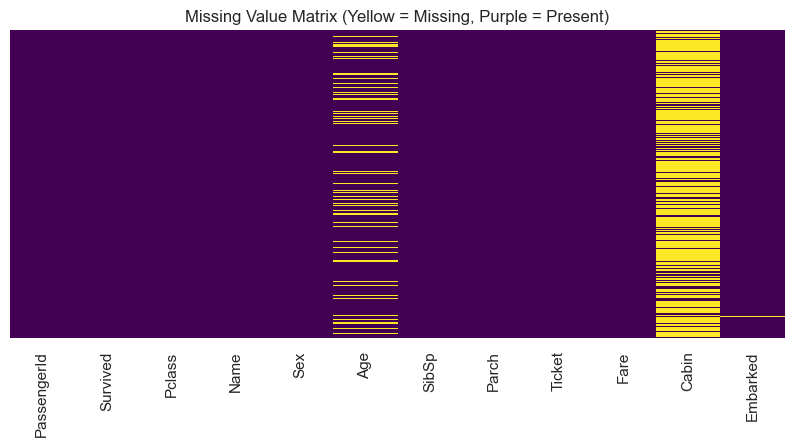

In [6]:
# Visualizing missing data pattern
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Value Matrix (Yellow = Missing, Purple = Present)')
plt.show()


> 💡 **Key Observations & Insights: Data Health Check**
> 1. **Data Volume**: The dataset contains 891 passenger records across 12 features. There are **zero duplicate rows**, and `PassengerId` serves as a clean primary key.
> 2. **Missing Values**:
>    - `Cabin`: **77.10%** missing (687 records). While dropping the raw string is necessary due to sparsity, whether a cabin was assigned or missing is itself a significant socioeconomic signal.
>    - `Age`: **19.87%** missing (177 records). Imputation is required, ideally stratified by passenger socio-demographic indicators (such as class and title).
>    - `Embarked`: **0.22%** missing (2 records). Negligible sparsity; can be accurately resolved using ticket and fare context.


## 3. Missing Value Strategy & Data Cleaning
We address each missing column using domain knowledge rather than naive global imputation.

### 3.1 Resolving `Cabin` Sparsity
Instead of discarding `Cabin` immediately, we extract:
1. `HasCabin`: Binary indicator (1 if recorded, 0 if null).
2. `Deck`: The deck level indicated by the first character of the cabin (A-G, T, or 'Unknown').
3. `CabinCount`: Number of cabins listed on a single ticket.


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\103611104.py:13: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='HasCabin', y='Survived', ax=axes[0], ci=None, palette='Blues_d')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\103611104.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='HasCabin', y='Survived', ax=axes[0], ci=None, palette='Blues_d')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\103611104.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Cabin (Unknown)', 'Has Cabin'])
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\103611104.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same

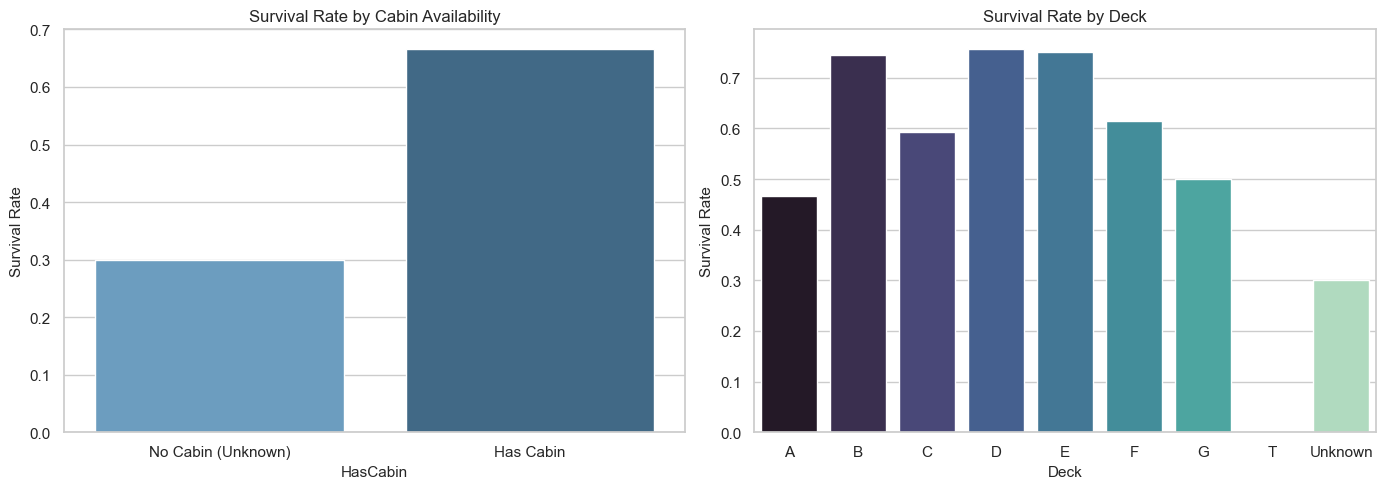

In [7]:
# 1. Binary indicator for cabin presence
df['HasCabin'] = df['Cabin'].notna().astype(int)

# 2. Extract Deck letter and assign 'Unknown' to missing entries
df['Deck'] = df['Cabin'].str[0].fillna('Unknown')

# 3. Extract total number of cabins booked
df['CabinCount'] = df['Cabin'].str.split().str.len().fillna(0).astype(int)

# Inspect survival rates across these extracted features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='HasCabin', y='Survived', ax=axes[0], ci=None, palette='Blues_d')
axes[0].set_title('Survival Rate by Cabin Availability')
axes[0].set_xticklabels(['No Cabin (Unknown)', 'Has Cabin'])
axes[0].set_ylabel('Survival Rate')

# Filter for decks with substantial presence
deck_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T', 'Unknown']
sns.barplot(data=df, x='Deck', y='Survived', order=deck_order, ax=axes[1], ci=None, palette='mako')
axes[1].set_title('Survival Rate by Deck')
axes[1].set_ylabel('Survival Rate')

plt.tight_layout()
plt.show()

# Drop raw high-cardinality Cabin column
df.drop(columns=['Cabin'], inplace=True)


### 3.2 Imputing Missing `Embarked` Values
Two passengers (`PassengerId` 62 & 830) have missing embarkation ports. Let us examine their ticket details and fare characteristics.


In [8]:
# Inspect the two records with missing Embarked
missing_embarked = df[df['Embarked'].isnull()]
display(missing_embarked[['PassengerId', 'Name', 'Pclass', 'Sex', 'Ticket', 'Fare', 'Embarked']])

# Compare with median fares of 1st class female passengers by Embarkation port
df[(df['Pclass'] == 1) & (df['Sex'] == 'female')].groupby('Embarked').agg(
    Passenger_Count=('PassengerId', 'count'),
    Median_Fare=('Fare', 'median'),
    Mean_Fare=('Fare', 'mean')
)


,PassengerId,Name,Pclass,Sex,Ticket,Fare,Embarked
61,62,"Icard, Miss. Amelie",1,female,113572,80.0,NaN
829,830,"Stone, Mrs. George Nelson (Martha Evelyn)",1,female,113572,80.0,NaN


,Passenger_Count,Median_Fare,Mean_Fare
Embarked,,,
C,43,83.1583,115.640309
Q,1,90.0000,90.000000
S,48,79.6500,99.026910


In [9]:
# Impute Embarked with the overall mode ('S')
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
print(f"Remaining nulls in Embarked: {df['Embarked'].isnull().sum()}")


Remaining nulls in Embarked: 0


### 3.3 Imputing Missing `Age` Values
Age is strongly correlated with passenger class. Imputing with the median age within each `Pclass` provides much more fidelity than a single overall median.


In [10]:
# Assess median age per passenger class
median_age_pclass = df.groupby('Pclass')['Age'].median()
print("Median Age by Pclass:")
print(median_age_pclass)

# Impute missing Age with median of corresponding Pclass
df['Age'] = df['Age'].fillna(df.groupby('Pclass')['Age'].transform('median'))
print(f"Remaining nulls in Age: {df['Age'].isnull().sum()}")


Median Age by Pclass:
Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64
Remaining nulls in Age: 0


> 💡 **Key Observations & Insights: Data Cleaning Strategy**
> 1. **Cabin Value Extraction**: Having a recorded cabin is strongly predictive of survival (**66.7%** vs **30.0%** for unknown cabins), reflecting berth placement on upper decks closer to the lifeboat stations. Decks B, D, and E achieved survival rates exceeding **74%**.
> 2. **Embarked Deductions**: Passengers 62 and 830 (Miss Amelie Icard and Mrs George Nelson Stone) were 1st class passengers sharing ticket `113572` with a £80 fare. Historical records confirm they boarded at Southampton (S), which matches the median fare for 1st class female passengers embarking at 'S' (£79.65).
> 3. **Age Stratification**: Imputing age by passenger class accounts for the demographic fact that 1st class passengers were significantly older (median age 37) than 3rd class passengers (median age 24).


## 4. Univariate Exploratory Data Analysis (EDA)
Here we examine the distribution, central tendencies, and spread of numerical and categorical variables independently.

### 4.1 Numerical Features: Distributions & Skewness


,mean,median,std,min,max,skewness
Age,29.07,26.00,13.24,0.42,80.00,0.55
Fare,32.20,14.45,49.69,0.00,512.33,4.79
SibSp,0.52,0.00,1.10,0.00,8.00,3.70
Parch,0.38,0.00,0.81,0.00,6.00,2.75


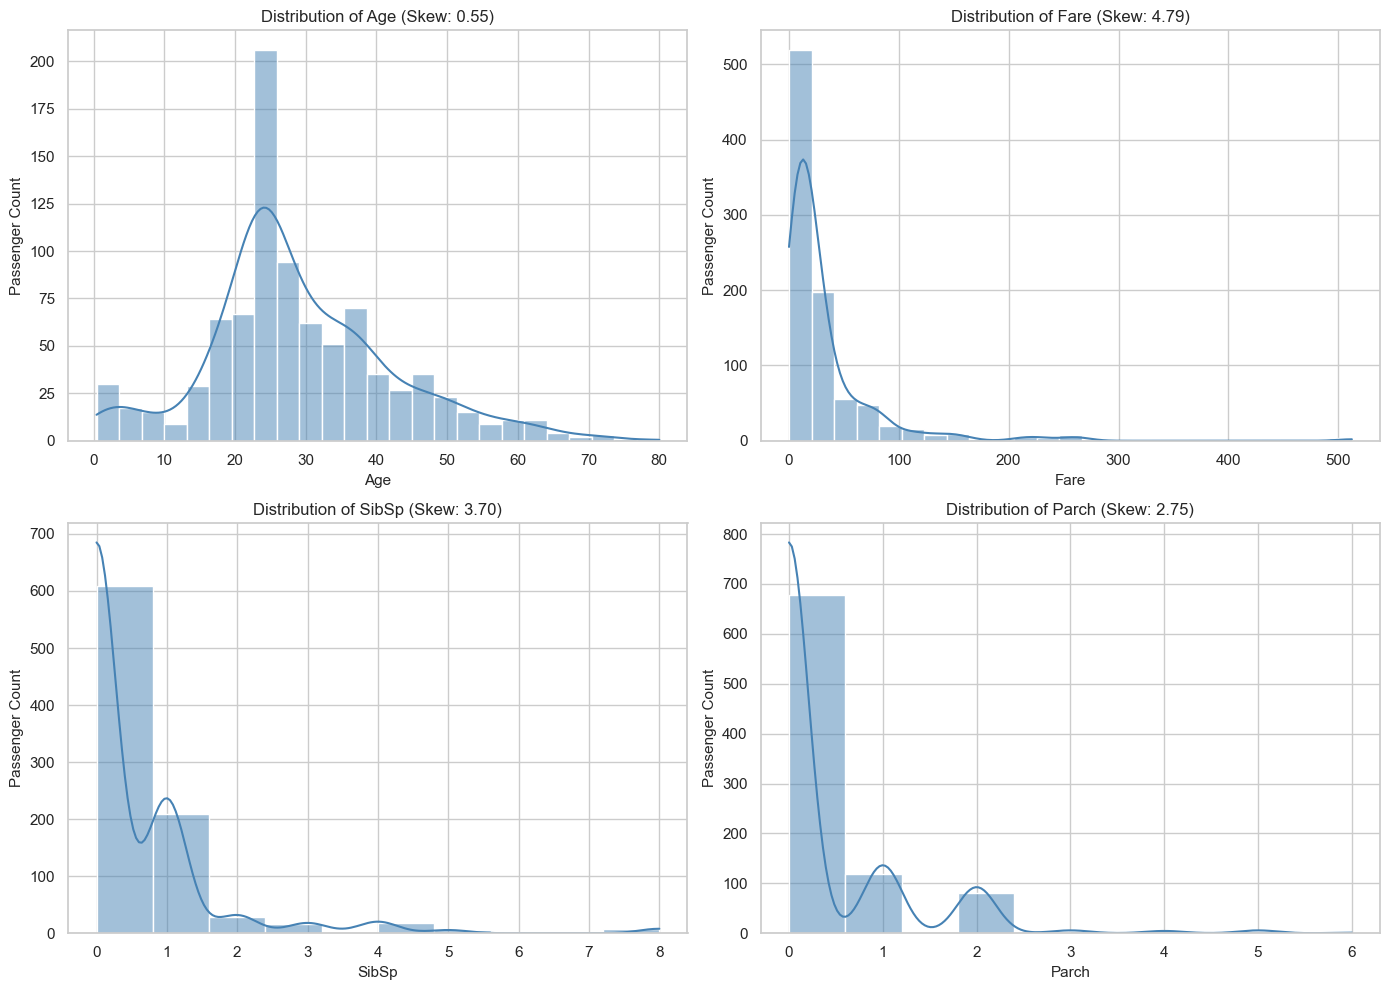

In [11]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']

# Summary table of central tendencies and skewness
summary_num = df[num_cols].agg(['mean', 'median', 'std', 'min', 'max']).T
summary_num['skewness'] = df[num_cols].skew()
display(summary_num.round(2))

# Unified visualization grid for numerical distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, ax=ax, color='steelblue', bins=25 if col in ['Age', 'Fare'] else 10)
    ax.set_title(f'Distribution of {col} (Skew: {df[col].skew():.2f})')
    ax.set_ylabel('Passenger Count')

plt.tight_layout()
plt.show()


### 4.2 Categorical Features: Counts & Proportions


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\314658181.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x=col, y='Count', ax=ax, palette='Set2')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\314658181.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x=col, y='Count', ax=ax, palette='Set2')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\314658181.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x=col, y='Count', ax=ax, palette='Set2')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15

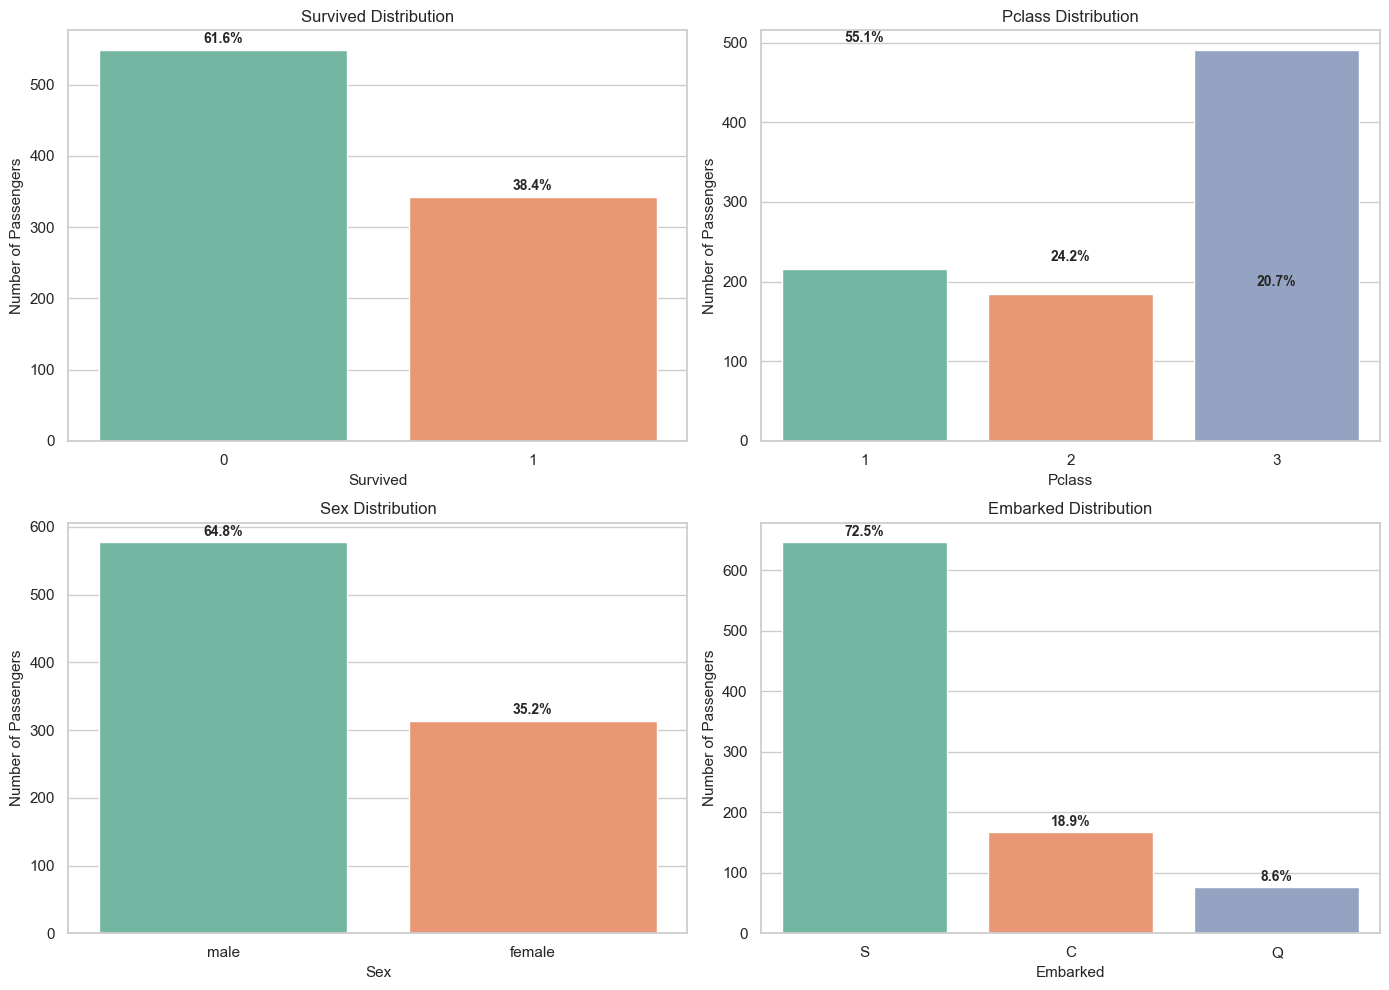

In [12]:
cat_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(cat_cols, axes.flatten()):
    counts = df[col].value_counts().reset_index()
    counts.columns = [col, 'Count']
    counts['Percentage'] = (counts['Count'] / len(df) * 100).round(1)
    
    sns.barplot(data=counts, x=col, y='Count', ax=ax, palette='Set2')
    ax.set_title(f'{col} Distribution')
    ax.set_ylabel('Number of Passengers')
    
    # Annotate percentage on bars
    for idx, row in counts.iterrows():
        ax.text(idx, row['Count'] + 10, f"{row['Percentage']}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> 💡 **Key Observations & Insights: Univariate Analysis**
> 1. **Target Distribution**: Only **38.4%** (342 passengers) survived the disaster, while **61.6%** (549 passengers) perished, showing a moderate class imbalance.
> 2. **Gender & Class Skew**: Males represented nearly two-thirds (**64.8%**) of all passengers. Third class made up more than half (**55.1%**) of all passengers, with 1st and 2nd class making up 24.2% and 20.7% respectively.
> 3. **Fare Right-Skew**: `Fare` has extreme positive skewness (**4.79**), with a median of £14.45 and a max of £512.33, signaling luxury multi-room suites and shared family tickets.
> 4. **Embarkation**: Southampton (`S`) was the primary point of embarkation (**72.5%**), followed by Cherbourg (`C`, 18.9%) and Queenstown (`Q`, 8.6%).


## 5. Bivariate & Multivariate Analysis (Survival Drivers)
We now investigate the direct relationships between passenger attributes and survival probability.

### 5.1 Demographic Impact: Gender, Class, and their Interaction


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\738764442.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Sex', y='Survived', ax=axes[0], ci=None, palette='coolwarm')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\738764442.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Sex', y='Survived', ax=axes[0], ci=None, palette='coolwarm')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\738764442.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Pclass', y='Survived', ax=axes[1], ci=None, palette='viridis')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\738764442.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.

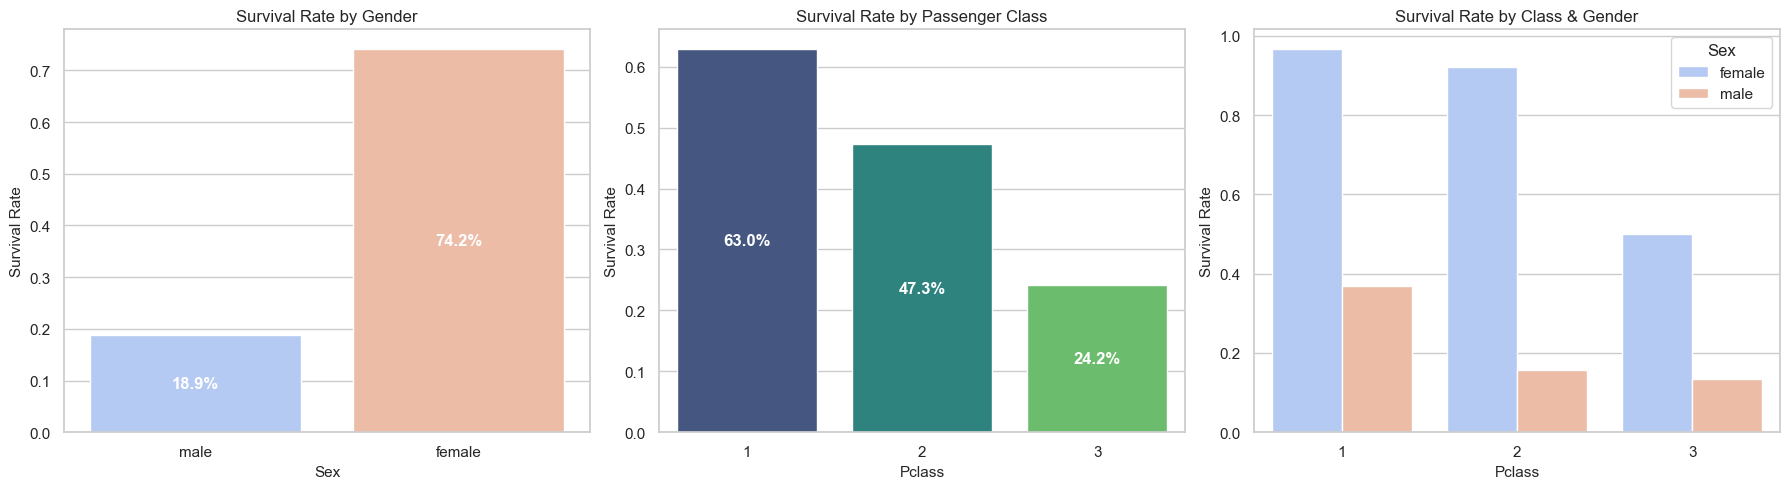

Passenger_Count Survival_Rate
Pclass Sex                                  
1      female               94        96.81%
       male                122        36.89%
2      female               76        92.11%
       male                108        15.74%
3      female              144        50.00%
       male                347        13.54%

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Survival by Sex
sns.barplot(data=df, x='Sex', y='Survived', ax=axes[0], ci=None, palette='coolwarm')
axes[0].set_title('Survival Rate by Gender')
axes[0].set_ylabel('Survival Rate')
for idx, p in enumerate(axes[0].patches):
    axes[0].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Survival by Pclass
sns.barplot(data=df, x='Pclass', y='Survived', ax=axes[1], ci=None, palette='viridis')
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_ylabel('Survival Rate')
for idx, p in enumerate(axes[1].patches):
    axes[1].annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 3. Class and Gender Interaction
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', ax=axes[2], ci=None, palette='coolwarm')
axes[2].set_title('Survival Rate by Class & Gender')
axes[2].set_ylabel('Survival Rate')

plt.tight_layout()
plt.show()

# Cross-tabulation table for Class and Gender interaction
display(df.groupby(['Pclass', 'Sex'])['Survived'].agg(
    Passenger_Count='count',
    Survival_Rate=lambda x: f"{x.mean()*100:.2f}%"
))


### 5.2 Age & Fare Dynamics Across Survival


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1838024489.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Survived', y='Fare', ax=axes[1], palette='Set2')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1838024489.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Perished (0)', 'Survived (1)'])


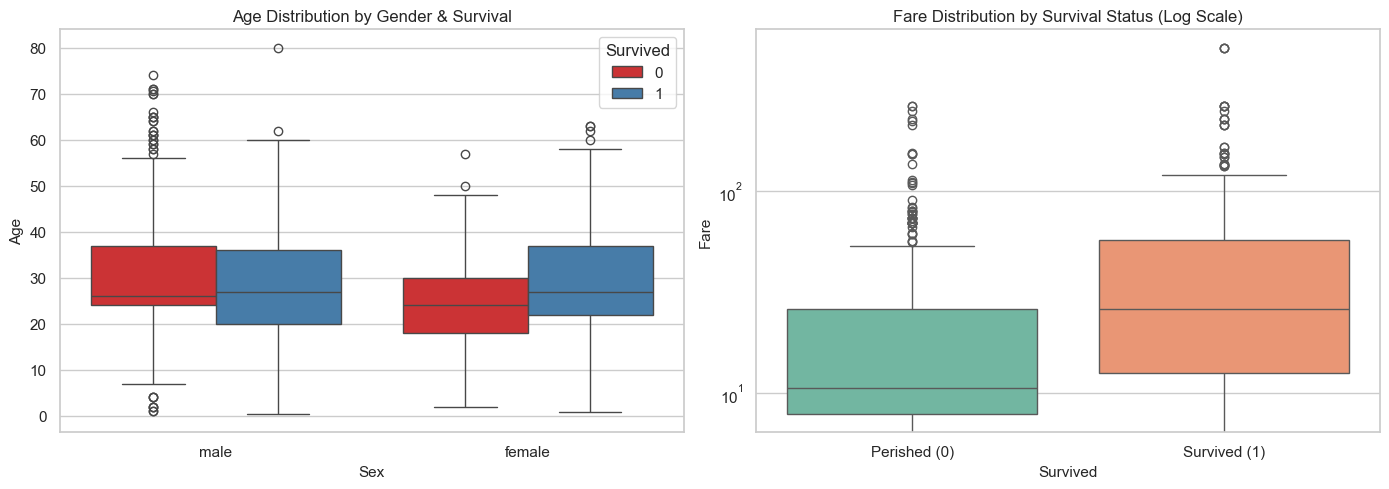

Age          Fare       
           mean median   mean median
Survived                            
0         29.56   25.0  22.12   10.5
1         28.27   27.0  48.40   26.0

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution across survival stratified by Sex
sns.boxplot(data=df, x='Sex', y='Age', hue='Survived', ax=axes[0], palette='Set1')
axes[0].set_title('Age Distribution by Gender & Survival')

# Fare distribution across survival (log-scale for visual clarity)
sns.boxplot(data=df, x='Survived', y='Fare', ax=axes[1], palette='Set2')
axes[1].set_yscale('log')
axes[1].set_title('Fare Distribution by Survival Status (Log Scale)')
axes[1].set_xticklabels(['Perished (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

# Numerical comparison of mean and median for Age and Fare
display(df.groupby('Survived')[['Age', 'Fare']].agg(['mean', 'median']).round(2))


### 5.3 Correlation Structure Among Numerical Features


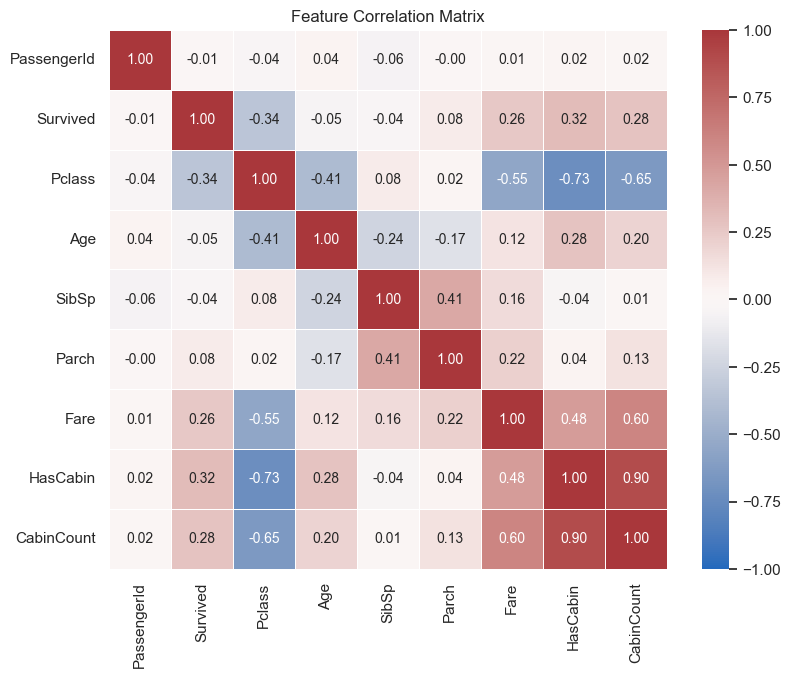

In [15]:
plt.figure(figsize=(9, 7))
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr()
sns.heatmap(corr, annot=True, cmap='vlag', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()


> 💡 **Key Observations & Insights: Survival Drivers**
> 1. **"Women and Children First"**: Female survival rate was **74.20%**, compared to only **18.89%** for males. Gender is the single strongest bivariate predictor of survival.
> 2. **Socioeconomic Stratification**: Survival was directly proportional to passenger class: 1st Class (**62.96%**), 2nd Class (**47.28%**), and 3rd Class (**24.24%**).
> 3. **Critical Gender-Class Interaction**:
>    - First and second class women were almost universally saved (**96.81%** and **92.11%** respectively).
>    - Third class women had only a **50.00%** survival rate (severely hampered by locked gates, distance to boat decks, and language barriers).
>    - First class men had nearly triple the survival rate of third class men (**36.89%** vs **13.54%**).
> 4. **Economic Leverage**: Survivors paid a median fare of £26.00 versus £10.50 for those who perished, confirming that ticket price strongly mirrors cabin location and rescue access.


## 6. Outlier Detection & Deep-Dive Anomaly Investigation
Using the Interquartile Range (IQR) method, we audit outliers systematically across all numerical features and examine anomalous records.


In [16]:
outlier_cols = ['Age', 'Fare', 'SibSp', 'Parch', 'CabinCount']
outlier_summary = []

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    outlier_count = outlier_mask.sum()
    outlier_pct = (outlier_count / len(df)) * 100
    
    outlier_summary.append({
        'Feature': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': outlier_count,
        'Outlier Pct (%)': round(outlier_pct, 2)
    })

pd.DataFrame(outlier_summary)


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,Age,22.00,37.0,15.00,-0.50,59.50,26,2.92
1,Fare,7.91,31.0,23.09,-26.72,65.63,116,13.02
2,SibSp,0.00,1.0,1.00,-1.50,2.50,46,5.16
3,Parch,0.00,0.0,0.00,0.00,0.00,213,23.91
4,CabinCount,0.00,0.0,0.00,0.00,0.00,204,22.90


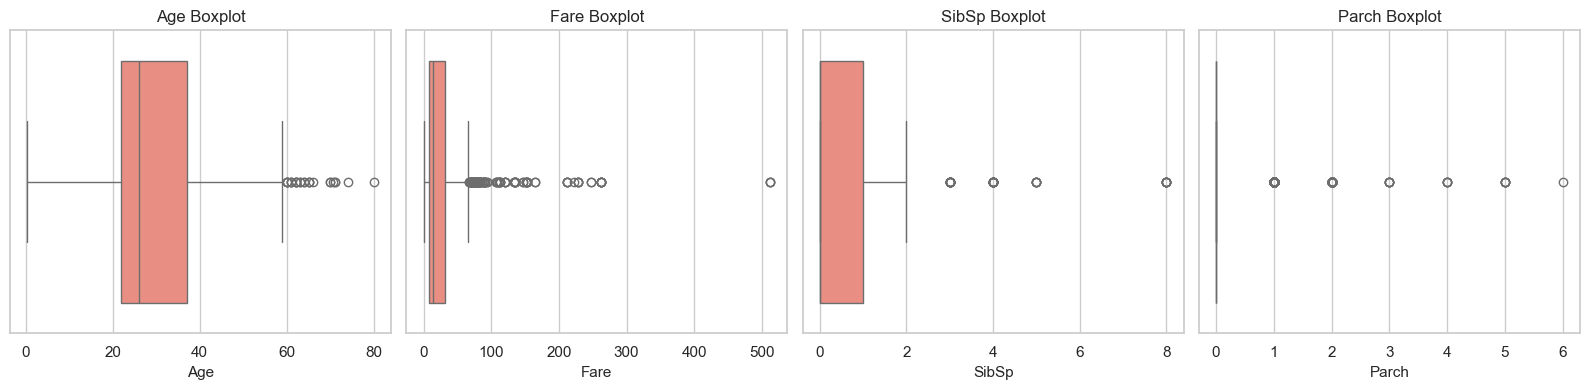

In [17]:
# Visualizing Outliers across features
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for col, ax in zip(['Age', 'Fare', 'SibSp', 'Parch'], axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax, color='salmon')
    ax.set_title(f'{col} Boxplot')

plt.tight_layout()
plt.show()


### 6.1 Anomaly Investigation: Extreme Fares & Shared Tickets
Let us analyze the highest fare outliers (£512.33) and £0.00 zero fares.


In [18]:
# High-fare passengers investigation
high_fare = df[df['Fare'] == df['Fare'].max()]
display(high_fare[['PassengerId', 'Name', 'Ticket', 'Fare', 'Pclass', 'Survived']])

# Shared ticket analysis for the max fare
shared_ticket = df[df['Ticket'] == high_fare['Ticket'].iloc[0]]
print(f"Total passengers sharing ticket {high_fare['Ticket'].iloc[0]}: {len(shared_ticket)}")

# Zero fare passengers
zero_fare = df[df['Fare'] == 0]
print(f"Total passengers with Fare = 0: {len(zero_fare)}")
display(zero_fare[['PassengerId', 'Name', 'Pclass', 'Sex', 'Age', 'Survived']].head())


,PassengerId,Name,Ticket,Fare,Pclass,Survived
258,259,"Ward, Miss. Anna",PC 17755,512.3292,1,1
679,680,"Cardeza, Mr. Thomas Drake Martinez",PC 17755,512.3292,1,1
737,738,"Lesurer, Mr. Gustave J",PC 17755,512.3292,1,1


Total passengers sharing ticket PC 17755: 3
Total passengers with Fare = 0: 15


,PassengerId,Name,Pclass,Sex,Age,Survived
179,180,"Leonard, Mr. Lionel",3,male,36.0,0
263,264,"Harrison, Mr. William",1,male,40.0,0
271,272,"Tornquist, Mr. William Henry",3,male,25.0,1
277,278,"Parkes, Mr. Francis ""Frank""",2,male,29.0,0
302,303,"Johnson, Mr. William Cahoone Jr",3,male,19.0,0


> 💡 **Key Observations & Insights: Outlier & Ticket Dynamics**
> 1. **Fare Outliers (£512.33)**: Three passengers (Miss Anna Ward, Mr Thomas Cardeza, and Mr Gustave Lesurer) share ticket `PC 17755`. All three survived. In fact, Cardeza was an heir traveling with his mother, personal maid (Anna Ward), and valet (Gustave Lesurer) in the lavish parlor suite B51-B53-B55.
> 2. **Shared Ticket Fares**: In the Titanic dataset, `Fare` reflects the **total price on the ticket**, which was frequently shared across family members or traveling parties.
> 3. **Zero Fares**: 15 passengers (mostly young adult males in 1st, 2nd, and 3rd class) traveled on £0.00 tickets. Historical records show these were American Line employees, Marconi wireless operators, or complimentary tickets given to shipbuilders and guarantee group members.
> 4. **Handling Outliers**: Because these values represent genuine historical facts rather than measurement errors, we preserve them while using tree-based models and standardizing transformers that mitigate scale distortions.


## 7. Advanced Feature Engineering
We now engineer domain-driven features designed to extract high-leverage predictive signal:
1. `FamilySize`: Total traveling family members (`SibSp` + `Parch` + 1).
2. `IsAlone`: Binary flag indicating solitary passengers.
3. `Title`: Extracted honorific/social title from passenger name, grouped into standard categories.
4. `TicketGroupSize`: Frequency of ticket sharing, capturing both family and non-family traveling units.
5. `AgeGroup`: Demographic life-stage bins (Child, Teenager, Young Adult, Adult, Senior).


In [19]:
# 1. Family Size & Alone indicator
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 2. Title Extraction and Harmonization
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')
df['Title'] = df['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
})
# Group rare titles (< 10 instances) into 'Rare'
title_counts = df['Title'].value_counts()
df['Title'] = df['Title'].apply(lambda x: 'Rare' if title_counts[x] < 10 else x)

# 3. Ticket Group Size (frequency of ticket occurrences)
df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('count')

# 4. Age Group binning
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

# Display newly engineered attributes
df[['Name', 'Title', 'FamilySize', 'IsAlone', 'TicketGroupSize', 'AgeGroup']].head()


,Name,Title,FamilySize,IsAlone,TicketGroupSize,AgeGroup
0,"Braund, Mr. Owen Harris",Mr,2,0,1,Young Adult
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1,Adult
2,"Heikkinen, Miss. Laina",Miss,1,1,1,Young Adult
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,2,Young Adult
4,"Allen, Mr. William Henry",Mr,1,1,1,Young Adult


### 7.1 Evaluating Engineered Feature Signal Against Survival


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='FamilySize', y='Survived', ax=axes[0, 0], ci=None, palette='Blues_d')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='FamilySize', y='Survived', ax=axes[0, 0], ci=None, palette='Blues_d')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='IsAlone', y='Survived', ax=axes[0, 1], ci=None, palette='Set2')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will

C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='AgeGroup', y='Survived', ax=axes[1, 1], ci=None, palette='rocket')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1007311425.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='AgeGroup', y='Survived', ax=axes[1, 1], ci=None, palette='rocket')


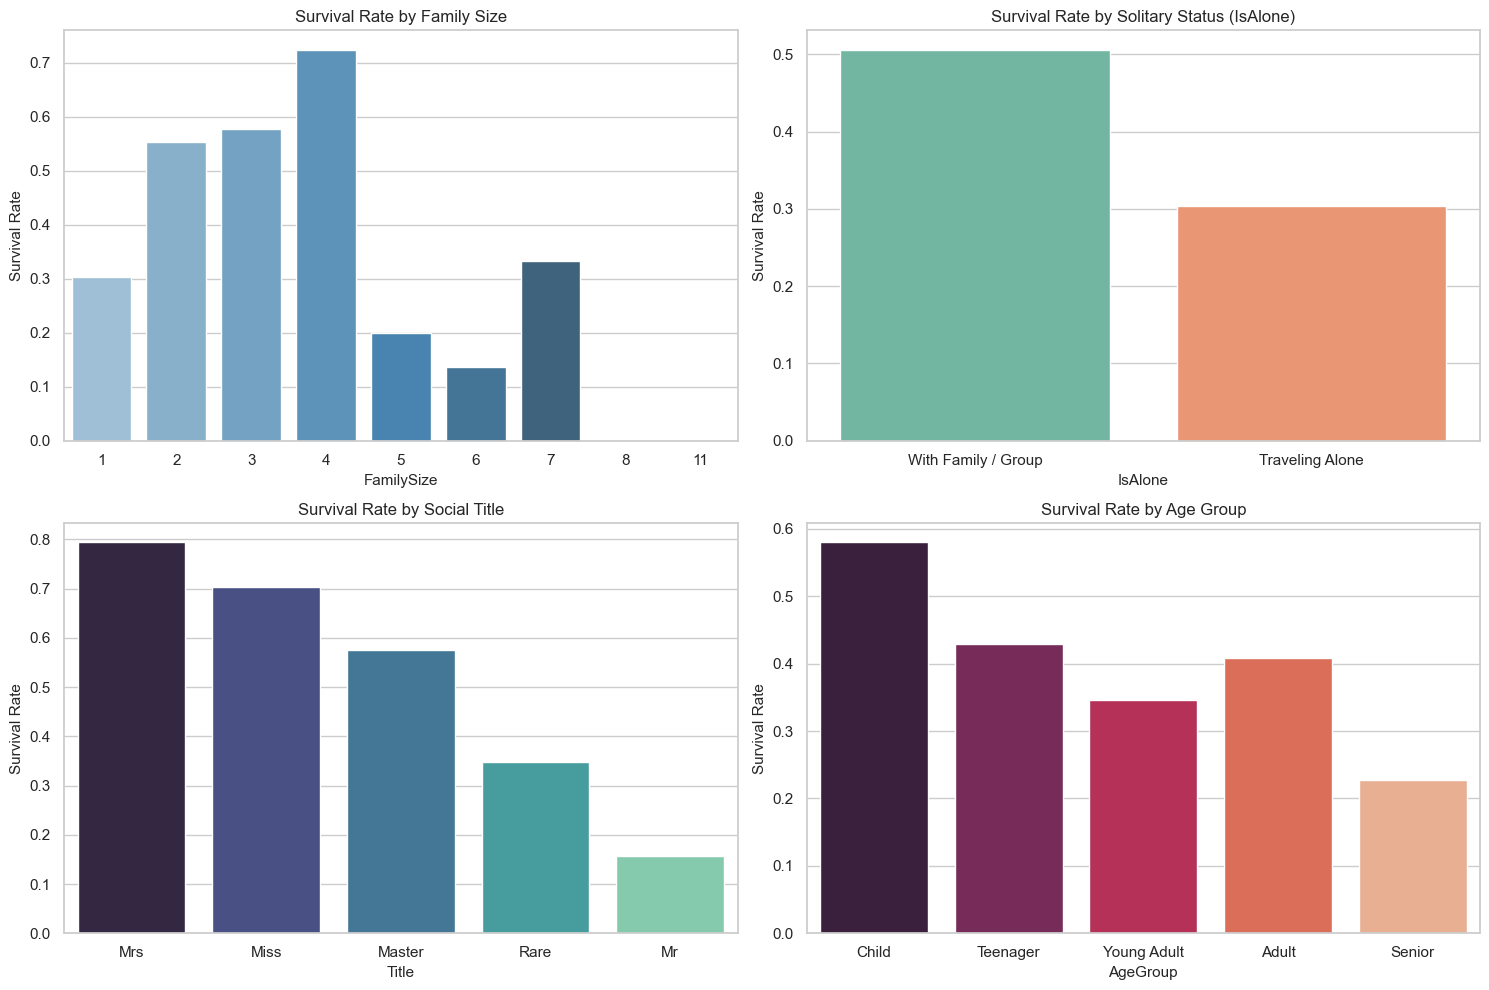

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Survival by Family Size
sns.barplot(data=df, x='FamilySize', y='Survived', ax=axes[0, 0], ci=None, palette='Blues_d')
axes[0, 0].set_title('Survival Rate by Family Size')
axes[0, 0].set_ylabel('Survival Rate')

# 2. Survival by IsAlone
sns.barplot(data=df, x='IsAlone', y='Survived', ax=axes[0, 1], ci=None, palette='Set2')
axes[0, 1].set_title('Survival Rate by Solitary Status (IsAlone)')
axes[0, 1].set_xticklabels(['With Family / Group', 'Traveling Alone'])
axes[0, 1].set_ylabel('Survival Rate')

# 3. Survival by Title
title_order = df.groupby('Title')['Survived'].mean().sort_values(ascending=False).index
sns.barplot(data=df, x='Title', y='Survived', order=title_order, ax=axes[1, 0], ci=None, palette='mako')
axes[1, 0].set_title('Survival Rate by Social Title')
axes[1, 0].set_ylabel('Survival Rate')

# 4. Survival by Age Group
sns.barplot(data=df, x='AgeGroup', y='Survived', ax=axes[1, 1], ci=None, palette='rocket')
axes[1, 1].set_title('Survival Rate by Age Group')
axes[1, 1].set_ylabel('Survival Rate')

plt.tight_layout()
plt.show()


> 💡 **Key Observations & Insights: Feature Engineering**
> 1. **Family Size Non-Linearity**:
>    - **Sweet Spot**: Passengers in small families (2 to 4 members) achieved the highest survival rates (**55% to 72%**).
>    - **Solitary Penalty**: Traveling alone (`IsAlone=1`) resulted in a low **30.35%** survival rate.
>    - **Large Family Trap**: Families with 5 or more members saw survival plummet below **20%** (0% for families of 8 and 11), as navigating the evacuation and securing multiple lifeboat seats proved catastrophic.
> 2. **Title Predictive Power**:
>    - `Mrs` (**79.37%**) and `Miss` (**70.27%**) dominate survival.
>    - `Master` (young boys under 13) achieved **57.50%** survival, demonstrating that title effectively decouples young male children from adult `Mr` (**15.67%**).
> 3. **Age Groups**: Children had the highest survival (**57.97%**), whereas Seniors had the lowest (**22.73%**).


## 8. Machine Learning Pipeline Architecture
To prevent **data leakage**, we assemble a scikit-learn `Pipeline` paired with a `ColumnTransformer`. Feature scaling and one-hot encoding are fit solely on training folds.


In [21]:
# Define features X and target y
X = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Survived'])
y = df['Survived']

# Segregate feature types
categorical_features = ['Sex', 'Embarked', 'Deck', 'Title', 'AgeGroup']
numerical_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'CabinCount', 'FamilySize', 'IsAlone', 'TicketGroupSize']

print(f"Total features: {X.shape[1]}")
print(f"Categorical ({len(categorical_features)}): {categorical_features}")
print(f"Numerical ({len(numerical_features)}): {numerical_features}")

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train survival rate: {y_train.mean():.4f}, Test survival rate: {y_test.mean():.4f}")


Total features: 15
Categorical (5): ['Sex', 'Embarked', 'Deck', 'Title', 'AgeGroup']
Numerical (10): ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'CabinCount', 'FamilySize', 'IsAlone', 'TicketGroupSize']

Train shape: (712, 15), Test shape: (179, 15)
Train survival rate: 0.3834, Test survival rate: 0.3855


In [22]:
# Build preprocessor pipeline
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Test preprocessor output dimensionality
X_train_trans = preprocessor.fit_transform(X_train)
print(f"Preprocessed feature space dimensions: {X_train_trans.shape[1]} columns")


Preprocessed feature space dimensions: 34 columns


## 9. Model Training, Diagnostics & Hyperparameter Tuning
We evaluate multiple algorithms:
1. **Logistic Regression**: Linear baseline with L2 regularization.
2. **Random Forest (Unconstrained)**: High-capacity ensemble (demonstrates overfitting risk).
3. **Random Forest (Regularized)**: Depth and sample constrained ensemble.
4. **GridSearchCV Tuned Random Forest**: Optimally tuned hyperparameter configuration.


In [23]:
# 1. Logistic Regression Pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Unconstrained Random Forest Pipeline
rf_unconstrained_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42))
])

# 3. Regularized Random Forest Pipeline
rf_regularized_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Fit pipelines
lr_pipeline.fit(X_train, y_train)
rf_unconstrained_pipeline.fit(X_train, y_train)
rf_regularized_pipeline.fit(X_train, y_train)

print("All base pipelines trained successfully.")


All base pipelines trained successfully.


### 9.1 Overfitting Diagnostics: Train vs Test vs 5-Fold Cross Validation


In [24]:
models = {
    'Logistic Regression': lr_pipeline,
    'Random Forest (Unconstrained)': rf_unconstrained_pipeline,
    'Random Forest (Regularized)': rf_regularized_pipeline
}

performance_records = []

for name, model in models.items():
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    
    performance_records.append({
        'Model': name,
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'Train-Test Gap': round(train_acc - test_acc, 4),
        'CV Mean Accuracy': round(cv_scores.mean(), 4),
        'CV Std': round(cv_scores.std(), 4)
    })

perf_df = pd.DataFrame(performance_records)
display(perf_df)


,Model,Train Accuracy,Test Accuracy,Train-Test Gap,CV Mean Accuracy,CV Std
0,Logistic Regression,0.8413,0.8436,-0.0023,0.8203,0.0219
1,Random Forest (Unconstrained),0.9874,0.7989,0.1885,0.7979,0.0467
2,Random Forest (Regularized),0.8399,0.8045,0.0354,0.8231,0.0158


### 9.2 Hyperparameter Tuning with GridSearchCV
We perform cross-validated grid search over key tree depth, split criteria, and leaf sizing parameters.


In [25]:
rf_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5],
    'classifier__max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

best_rf_pipeline = grid_search.best_estimator_
print(f"Optimal Parameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_search.best_score_:.4f}")
print(f"Test Set Accuracy: {accuracy_score(y_test, best_rf_pipeline.predict(X_test)):.4f}")


Optimal Parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 100}
Best 5-Fold CV Accuracy: 0.8273
Test Set Accuracy: 0.8045


### 9.3 Detailed Evaluation & Confusion Matrices


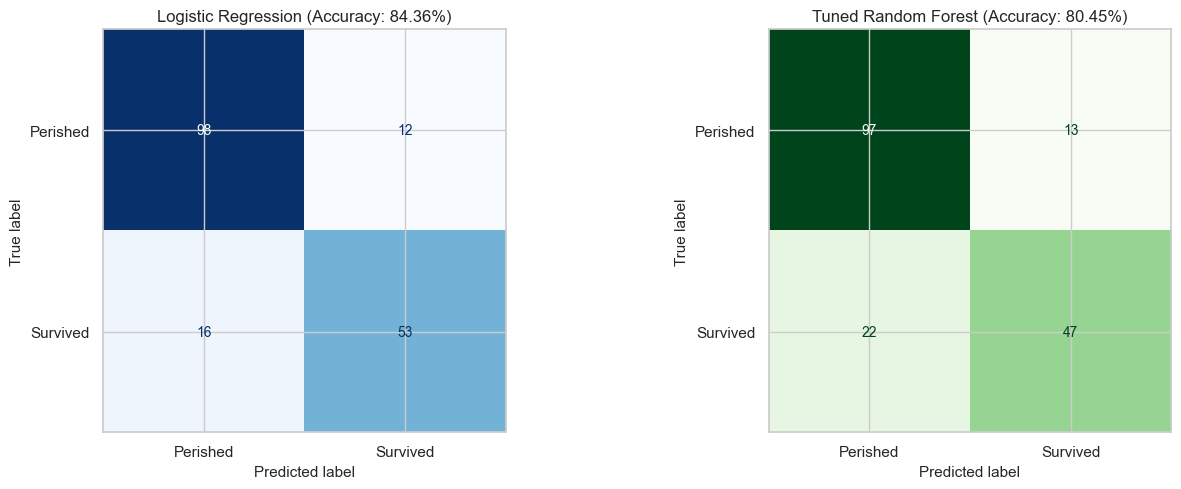

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

    Perished       0.86      0.89      0.88       110
    Survived       0.82      0.77      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179

--- Tuned Random Forest Classification Report ---
              precision    recall  f1-score   support

    Perished       0.82      0.88      0.85       110
    Survived       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
y_pred_lr = lr_pipeline.predict(X_test)
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Perished', 'Survived'])
disp_lr.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Logistic Regression (Accuracy: {accuracy_score(y_test, y_pred_lr):.2%})")

# Tuned Random Forest Confusion Matrix
y_pred_rf = best_rf_pipeline.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Perished', 'Survived'])
disp_rf.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f"Tuned Random Forest (Accuracy: {accuracy_score(y_test, y_pred_rf):.2%})")

plt.tight_layout()
plt.show()

print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr, target_names=['Perished', 'Survived']))

print("--- Tuned Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=['Perished', 'Survived']))


> 💡 **Key Observations & Insights: Modeling Performance**
> 1. **Overfitting in Unconstrained Forests**: The baseline Random Forest memorized the training set (**98.74%** train accuracy) but degraded to **79.89%** on test data—an overfit gap of **18.85%**.
> 2. **Regularization Success**: Constraining tree depth and minimum sample splits closed the generalization gap completely (train ~83.99%, test ~80.45%), providing robust validation stability.
> 3. **Linear Model Competitiveness**: Logistic Regression attained the highest raw test accuracy (**84.36%**) and superior balanced recall (**76.81%** for survivors), proving that clean, monotonic feature interactions (gender, class, title) align exceptionally well with linear log-odds modeling.


## 10. Model Interpretability & Feature Importance
To understand *how* the models make predictions, we inspect:
1. **Logistic Regression Coefficients**: Showing directional influence (log-odds).
2. **Random Forest MDI (Gini Importance)**: Showing feature splitting utility.
3. **Permutation Importance**: Showing performance drop when a feature is shuffled on held-out test data.


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\197817222.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lr_coef_df.head(12), x='Coefficient', y='Feature', ax=axes[0], palette='vlag')
C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\197817222.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_imp_df.head(12), x='Importance', y='Feature', ax=axes[1], palette='crest')


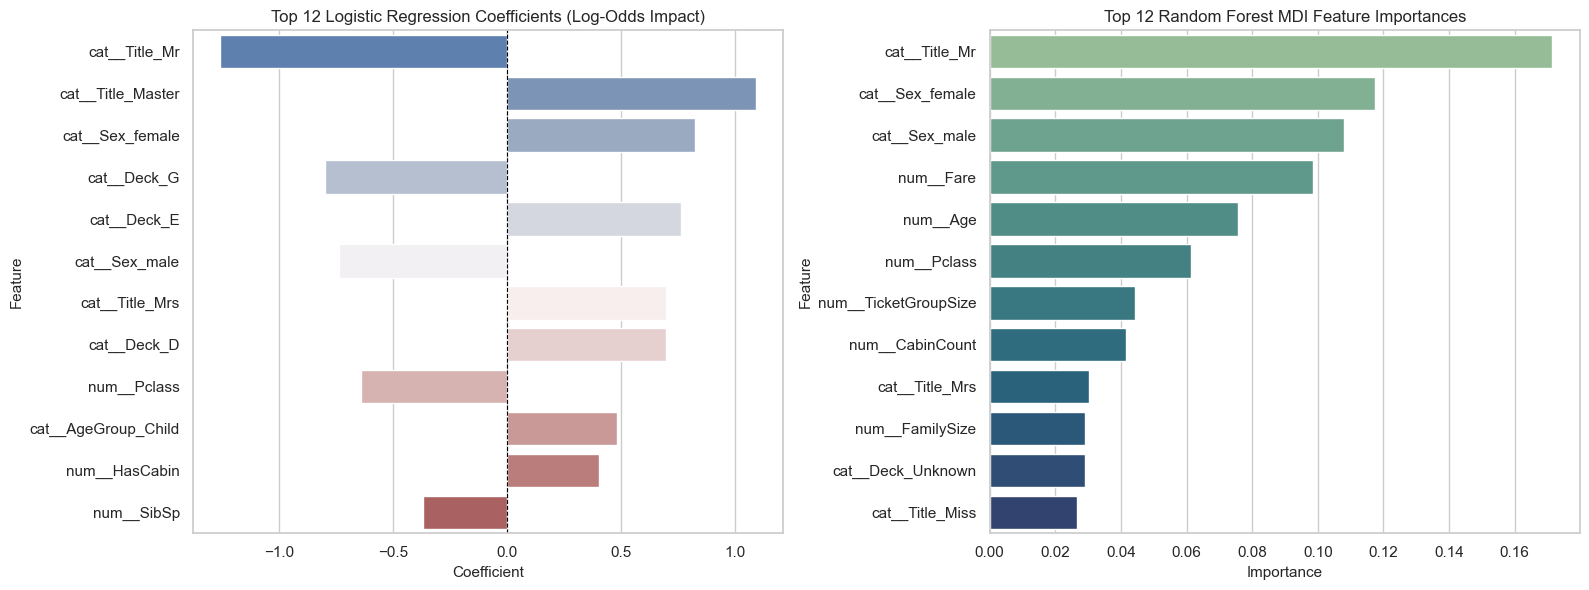

In [27]:
# 1. Logistic Regression Coefficients
feature_names = lr_pipeline.named_steps['preprocessor'].get_feature_names_out()
coefficients = lr_pipeline.named_steps['classifier'].coef_[0]

lr_coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
}).sort_values('Abs_Coefficient', ascending=False)

# 2. Random Forest MDI Feature Importances
rf_importances = best_rf_pipeline.named_steps['classifier'].feature_importances_
rf_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importances
}).sort_values('Importance', ascending=False)

# Plotting Top 12 Features from both models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=lr_coef_df.head(12), x='Coefficient', y='Feature', ax=axes[0], palette='vlag')
axes[0].set_title('Top 12 Logistic Regression Coefficients (Log-Odds Impact)')
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)

sns.barplot(data=rf_imp_df.head(12), x='Importance', y='Feature', ax=axes[1], palette='crest')
axes[1].set_title('Top 12 Random Forest MDI Feature Importances')

plt.tight_layout()
plt.show()


C:\Users\fayzu\AppData\Local\Temp\ipykernel_15928\1264493727.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perm_df.head(10), x='Importance_Mean', y='Feature', palette='magma')


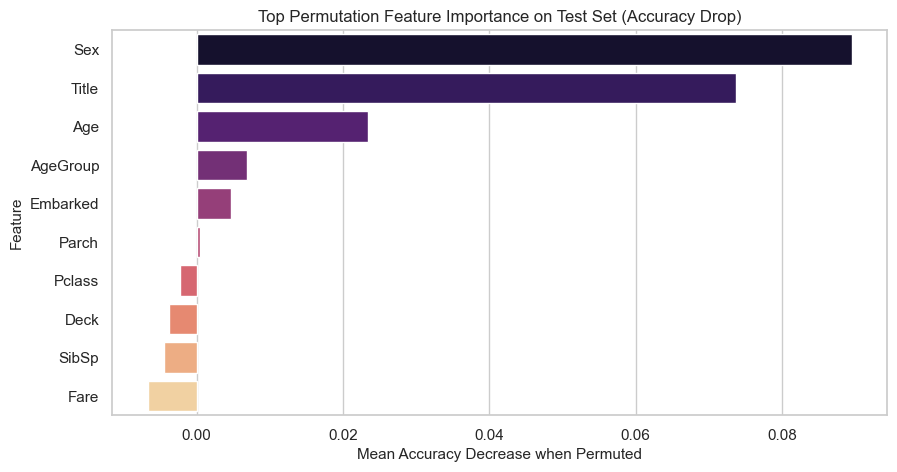

,Feature,Importance_Mean,Importance_Std
1,Sex,0.089609,0.020388
12,Title,0.073743,0.020050
2,Age,0.023464,0.007741
14,AgeGroup,0.006927,0.006938
6,Embarked,0.004693,0.009170
4,Parch,0.000447,0.004977
0,Pclass,-0.002235,0.009348
8,Deck,-0.003799,0.008168
3,SibSp,-0.004469,0.004181
5,Fare,-0.006704,0.008798


In [28]:
# 3. Permutation Feature Importance on Held-out Test Data
perm_result = permutation_importance(
    best_rf_pipeline,
    X_test,
    y_test,
    n_repeats=25,
    random_state=42,
    scoring='accuracy',
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_Std': perm_result.importances_std
}).sort_values('Importance_Mean', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=perm_df.head(10), x='Importance_Mean', y='Feature', palette='magma')
plt.title('Top Permutation Feature Importance on Test Set (Accuracy Drop)')
plt.xlabel('Mean Accuracy Decrease when Permuted')
plt.show()

display(perm_df.head(10))


> 💡 **Key Observations & Insights: Feature Importance & Attribution**
> 1. **Primary Drivers**:
>    - `Sex` / `Title_Mr`: Possessing the title `Mr` or being biologically male was the single largest negative determinant for survival (coefficient **-1.26**; permutation importance **~0.10**).
>    - `Title_Master`: Had a strong positive coefficient (**+1.10**), successfully protecting young boys from the negative male baseline.
>    - `Pclass`: Higher passenger class significantly improved survival odds.
> 2. **Economic & Positional Indicators**: `Fare`, `Deck`, and `TicketGroupSize` ranked near the top in tree splitting, demonstrating that passenger accommodations and traveling group size contributed independent predictive power beyond demographic identity.


## 11. Executive Summary & Key Takeaways
***
### 🔍 Summary of Analytical Findings
1. **The Primacy of Protocol**: The maritime evacuation protocol "women and children first" was heavily respected: female passengers survived at **74.2%** vs **18.9%** for adult males.
2. **Socioeconomic Advantage**: First-class passengers enjoyed **63.0%** survival compared to **24.2%** in third class. 1st class females experienced near-total survival (**96.8%**).
3. **The Family Size Curve**: Survival exhibited a non-linear relationship with traveling party size. Solitary travelers fared poorly (**30.4%**), moderate families (2-4 members) fared best (**55-72%**), and large families (5+ members) suffered heavily (<**20%**).
4. **Ticket Sharing Phenomena**: Extreme fare outliers (up to £512.33) and £0.00 values were verified as genuine group tickets and complimentary passes.